In [9]:
import os
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations

In [10]:
def W_true(z):
    return (
        -2.0 * np.exp(-z**2) / np.sqrt(np.pi)
        -2.0 * np.exp(-0.5 * z**2) / np.sqrt(2.0 * np.pi)
    )

def W_true_prime(z):
    return (
        4.0 * z * np.exp(-z**2) / np.sqrt(np.pi)
        + 2.0 * z * np.exp(-0.5 * z**2) / np.sqrt(2.0 * np.pi)
    )

# Grid and convolution
def make_offsets(Nx, dx):
    return np.arange(-(Nx - 1), Nx) * dx

def conv_valid(rho_snapshot, kernel_values, dx):
    return dx * np.convolve(rho_snapshot, kernel_values, mode="valid")

# Basis builders
def build_gaussian_basis(offsets):
    ws = np.arange(0.5, 5.0 + 1e-12, 0.5)

    Psi = []
    dPsi = []

    for w in ws:
        Psi.append(-1.0 / (12.0 * w) * np.exp(-w * offsets**2))
        dPsi.append(offsets / 6.0 * np.exp(-w * offsets**2))

    return {
        "name": "gaussian",
        "params": ws,
        "Psi": np.array(Psi),
        "dPsi": np.array(dPsi),
    }


def build_fourier_basis(offsets, Lbox=6.0, num_modes=20):
    modes = np.arange(1, num_modes + 1)

    Psi = []
    dPsi = []

    for k in modes:
        Psi.append(
            -(Lbox / (k * np.pi)) * np.cos(k * np.pi * offsets / Lbox)
        )
        dPsi.append(
            np.sin(k * np.pi * offsets / Lbox)
        )

    return {
        "name": "fourier",
        "params": modes,
        "Psi": np.array(Psi),
        "dPsi": np.array(dPsi),
        "Lbox": Lbox,
    }


def build_polynomial_basis(offsets, powers=None, Lbox=6.0):
    if powers is None:
        powers = np.array([1, 3, 5, 7, 9, 11])

    s = offsets / Lbox

    Psi = []
    dPsi = []

    for p in powers:
        Psi.append(s ** (p + 1) / (p + 1))
        dPsi.append(s ** p / Lbox)

    return {
        "name": "polynomial",
        "params": powers,
        "Psi": np.array(Psi),
        "dPsi": np.array(dPsi),
        "Lbox": Lbox,
    }


# Restricted LS / RE pruning
def restricted_least_squares(A, b, support):
    support = np.array(sorted(support))
    c = np.zeros(A.shape[1])
    c[support] = np.linalg.pinv(A[:, support]) @ b
    RE = c.T @ A @ c - 2.0 * c.T @ b
    residual = np.linalg.norm(A @ c - b)
    return c, RE, residual

def re_pruning(A, b, candidate_support, sparsity):
    candidate_support = sorted(set(candidate_support))
    records = []
    for J in combinations(candidate_support, sparsity):
        cJ, RE, residual = restricted_least_squares(A, b, J)
        records.append({
            "support": tuple(J),
            "coef": cJ,
            "RE": RE,
            "residual": residual,
        })
    records = sorted(records, key=lambda r: r["RE"])
    return records


# Reconstruction
def reconstruct_from_basis(c, Psi_plot, dPsi_plot):
    W_hat = np.zeros_like(Psi_plot[0])
    Wp_hat = np.zeros_like(dPsi_plot[0])
    for ci, Pi, dPi in zip(c, Psi_plot, dPsi_plot):
        W_hat += ci * Pi
        Wp_hat += ci * dPi
    return W_hat, Wp_hat

def align_constant(W_hat, W_ref):
    return W_hat - np.mean(W_hat - W_ref)

def rel_L2_mask(f_hat, f_ref, mask):
    return (
        np.linalg.norm(f_hat[mask] - f_ref[mask])
        / np.linalg.norm(f_ref[mask])
    )

def rel_L2_interval(z, f_hat, f_ref, interval):
    a, b = interval
    mask = (z >= a) & (z <= b)
    dz = z[1] - z[0]
    return (np.sqrt(dz * np.sum((f_hat[mask] - f_ref[mask]) ** 2)) / np.sqrt(dz * np.sum(f_ref[mask] ** 2)))

def build_plot_basis(kind, z_plot, params, Lbox=6.0):
    Psi_plot = []
    dPsi_plot = []
    if kind == "gaussian":
        for w in params:
            Psi_plot.append(-1.0 / (12.0 * w) * np.exp(-w * z_plot**2))
            dPsi_plot.append(z_plot / 6.0 * np.exp(-w * z_plot**2))
    elif kind == "fourier":
        for k in params:
            Psi_plot.append(-(Lbox / (k * np.pi)) * np.cos(k * np.pi * z_plot / Lbox))
            dPsi_plot.append(np.sin(k * np.pi * z_plot / Lbox))
    elif kind == "polynomial":
        s = z_plot / Lbox
        for p in params:
            Psi_plot.append(s ** (p + 1) / (p + 1))
            dPsi_plot.append(s ** p / Lbox)

    else:
        raise ValueError("Unknown basis type.")
    return np.array(Psi_plot), np.array(dPsi_plot)

def build_A_b_variational(rho, x, t, Psi, dPsi, m, kappa):

    dx = x[1] - x[0]
    dt = t[1] - t[0]
    T  = t[-1] - t[0]

    Nt, Nx = rho.shape
    n_basis = Psi.shape[0]

    A = np.zeros((n_basis, n_basis))
    b = np.zeros(n_basis)

    for ell in range(Nt - 1):

        rho_l = rho[ell]
        rho_next = rho[ell + 1]

        rho_t = (rho_next - rho_l) / dt

        Hprime = kappa * np.maximum(rho_l,0.0)**(m-1)
        Hprime_x = Dx_plus(Hprime, dx)

        F = rho_l * Hprime_x

        Psi_conv = np.zeros((n_basis, Nx))
        dPsi_conv = np.zeros((n_basis, Nx))

        for i in range(n_basis):
            Psi_conv[i] = conv_valid(rho_l, Psi[i], dx)
            dPsi_conv[i] = conv_valid(rho_l, dPsi[i], dx)

        for i in range(n_basis):

            b[i] += -dt*dx*np.sum(
                rho_t*Psi_conv[i]
                + dPsi_conv[i]*F
            )

            for j in range(n_basis):

                A[i,j] += dt*dx*np.sum(
                    rho_l*dPsi_conv[i]*dPsi_conv[j]
                )

    A /= T
    b /= T

    A = 0.5*(A+A.T)

    return A,b

# Forward difference
def Dx_plus(v, dx):
    out = np.empty_like(v)
    out[:-1] = (v[1:] - v[:-1]) / dx
    out[-1] = -v[-1] / dx
    return out

def partinv(A, b, K=2, max_iter=100, tol=1e-12):
    n = A.shape[1]

    # Initial proxy
    c_tilde = A.T @ b

    # Initial support: K largest entries
    I = np.argsort(np.abs(c_tilde))[-K:]

    support_history = []

    for _ in range(max_iter):
        I = np.array(sorted(I))
        support_history.append(tuple(I.tolist()))

        # Restricted least squares on current support
        A_I = A[:, I]
        c_I = np.linalg.pinv(A_I) @ b

        # Residual
        r = b - A_I @ c_I

        # Proxy update
        c_tilde = np.zeros(n)
        c_tilde[I] = c_I

        J = np.setdiff1d(np.arange(n), I)

        if len(J) > 0:
            c_tilde[J] = A[:, J].T @ r

        # New support
        I_new = np.argsort(np.abs(c_tilde))[-K:]

        if set(I_new.tolist()) == set(I.tolist()):
            I = np.array(sorted(I_new))
            break

        if np.linalg.norm(r) < tol:
            I = np.array(sorted(I_new))
            break

        I = I_new

    I = np.array(sorted(I))

    c = np.zeros(n)
    c[I] = np.linalg.pinv(A[:, I]) @ b

    support_history = list(dict.fromkeys(support_history))

    return c, I, support_history

# Run one basis
def run_one_basis(basis, rho, x, t, m, kappa, K_partinv=4, sparsity=2, plot_interval=(-6.0, 6.0), output_root="Figures_partinv_basis", tag="tag"):
    name = basis["name"]
    params = basis["params"]
    Psi = basis["Psi"]
    dPsi = basis["dPsi"]
    outdir = output_root
    os.makedirs(outdir, exist_ok=True)
    A, b = build_A_b_variational(rho=rho, x=x, t=t, Psi=Psi, dPsi=dPsi, m=m, kappa=kappa,)
    print("\n" + "=" * 72)
    print(f"Basis: {name}")
    print("=" * 72)
    print("A shape:", A.shape)
    print("cond(A):", np.linalg.cond(A))
    D = np.sqrt(np.maximum(np.diag(A), 1e-30))
    corr = A / np.outer(D, D)
    coherence = np.max(np.abs(corr - np.eye(len(params))))
    print("coherence:", coherence)
    c_part, supp_part, supp_hist = partinv(A, b, K=K_partinv, max_iter=100)
    candidate_support = sorted(set(np.concatenate([np.array(s) for s in supp_hist])))
    if len(candidate_support) < sparsity:
        candidate_support = supp_part.tolist()
    records = re_pruning(A, b, candidate_support=candidate_support, sparsity=sparsity)
    best = records[0]
    c_best = best["coef"]
    support_best = best["support"]
    print("\nPartInv final support:", supp_part)
    print("Candidate support:", candidate_support)
    print("\nBest RE support:", support_best)
    print("Best RE:", best["RE"])
    print("Residual:", best["residual"])
    print("\nRecovered active terms:")
    for idx in support_best:
        print(f"index={idx}, param={params[idx]}, coef={c_best[idx]:+.12e}")
    dx = x[1] - x[0]
    offsets = make_offsets(len(x), dx)
    mask = (offsets >= plot_interval[0]) & (offsets <= plot_interval[1])
    z_plot = offsets[mask]
    Psi_plot, dPsi_plot = build_plot_basis(
        kind=name,
        z_plot=z_plot,
        params=params,
        Lbox=basis.get("Lbox", 6.0),
    )
    W_hat_raw, Wp_hat = reconstruct_from_basis(
        c_best,
        Psi_plot,
        dPsi_plot,
    )
    W_ref = W_true(z_plot)
    Wp_ref = W_true_prime(z_plot)
    interval_errors = {}
    for R in [2, 4, 6]:
        mask_R = np.abs(z_plot) <= R
        W_hat_R = W_hat_raw + np.mean(W_ref[mask_R] - W_hat_raw[mask_R])
        err_W = rel_L2_mask(W_hat_R, W_ref, mask_R)
        err_Wp = rel_L2_mask(Wp_hat, Wp_ref, mask_R)
        interval_errors[R] = {
            "W": err_W,
            "Wp": err_Wp,
        }
    print("\nRelative L2 errors of W")
    print(f"[-2,2] : {interval_errors[2]['W']:.6e}")
    print(f"[-4,4] : {interval_errors[4]['W']:.6e}")
    print(f"[-6,6] : {interval_errors[6]['W']:.6e}")
    print("\nRelative L2 errors of W'")
    print(f"[-2,2] : {interval_errors[2]['Wp']:.6e}")
    print(f"[-4,4] : {interval_errors[4]['Wp']:.6e}")
    print(f"[-6,6] : {interval_errors[6]['Wp']:.6e}")
    W_hat = W_hat_raw + np.mean(W_ref - W_hat_raw)
    W_err = interval_errors[6]["W"]
    Wp_err = interval_errors[6]["Wp"]
    prefix = f"{tag}_{name}"
    
    plt.figure(figsize=(6.5, 4.5))
    plt.plot(z_plot, W_ref, "k-", lw=2.0, label="True W")
    plt.plot(z_plot, W_hat, "r--", lw=2.0, label="Learned W")
    plt.xlabel("z")
    plt.ylabel(r"$W(z)$")
    # plt.title(f"Example 2 learned potential: {name}")
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"{outdir}/{prefix}_sparse_W.png", dpi=300, bbox_inches="tight")
    plt.savefig(f"{outdir}/{prefix}_sparse_W.pdf", bbox_inches="tight")
    plt.show()

    plt.figure(figsize=(6.5, 4.5))
    plt.plot(z_plot, Wp_ref, "k-", lw=2.0, label="True W'")
    plt.plot(z_plot, Wp_hat, "r--", lw=2.0, label="Learned W'")
    plt.xlabel("z")
    plt.ylabel(r"$W'(z)$")
    #   plt.title(f"Example 2 learned force: {name}")
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"{outdir}/{prefix}_sparse_W_prime.png", dpi=300, bbox_inches="tight")
    plt.savefig(f"{outdir}/{prefix}_sparse_W_prime.pdf", bbox_inches="tight")
    plt.show()

    np.savez(
        f"{outdir}/{prefix}_sparse_result.npz",
        basis_name=name,
        params=params,
        A=A,
        b=b,
        c_best=c_best,
        support_best=np.array(support_best),
        c_partinv=c_part,
        support_partinv=supp_part,
        z_plot=z_plot,
        W_hat=W_hat,
        Wp_hat=Wp_hat,
        W_true=W_ref,
        Wp_true=Wp_ref,
        W_error=W_err,
        Wp_error=Wp_err,
        RE=best["RE"],
        residual=best["residual"],
    )

    return {
        "basis": name,
        "params": params,
        "coef": c_best,
        "support": support_best,
        "W_error_2": interval_errors[2]["W"],
        "Wp_error_2": interval_errors[2]["Wp"],
        "W_error_4": interval_errors[4]["W"],
        "Wp_error_4": interval_errors[4]["Wp"],
        "W_error_6": interval_errors[6]["W"],
        "Wp_error_6": interval_errors[6]["Wp"],
        "W_error": interval_errors[6]["W"],
        "Wp_error": interval_errors[6]["Wp"],
        "RE": best["RE"],
        "residual": best["residual"],
    }

Loaded: example2_sparse_Cx5_Ct250.npz
rho shape: (61, 192)
x range: -5.99375 5.94375
dx: 0.0625
t range: 0.0 1.5
dt: 0.025
m: 3
kappa: 0.48
offset range: -11.9375 11.9375

Basis: gaussian
A shape: (10, 10)
cond(A): 4.2860510900448216e+16
coherence: 0.9996284466935387

PartInv final support: [0 1 2 3]
Candidate support: [0, 1, 2, 3]

Best RE support: (0, 1)
Best RE: -0.1797728337362856
Residual: 4.657074988867638e-06

Recovered active terms:
index=0, param=0.5, coef=+5.331462627603e+00
index=1, param=1.0, coef=+1.241240997144e+01

Relative L2 errors of W
[-2,2] : 7.100068e-03
[-4,4] : 9.884277e-03
[-6,6] : 1.122925e-02

Relative L2 errors of W'
[-2,2] : 2.102379e-02
[-4,4] : 2.216278e-02
[-6,6] : 2.216280e-02


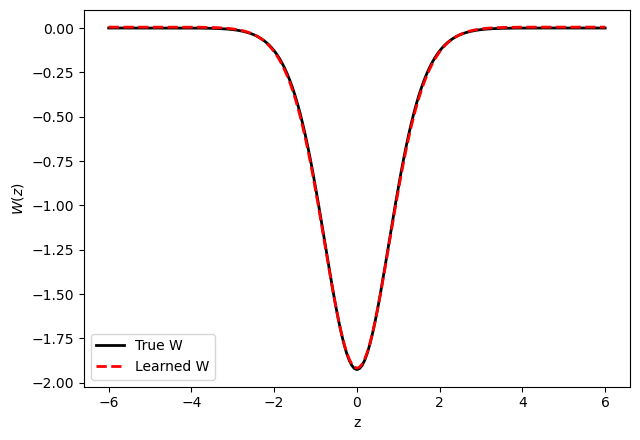

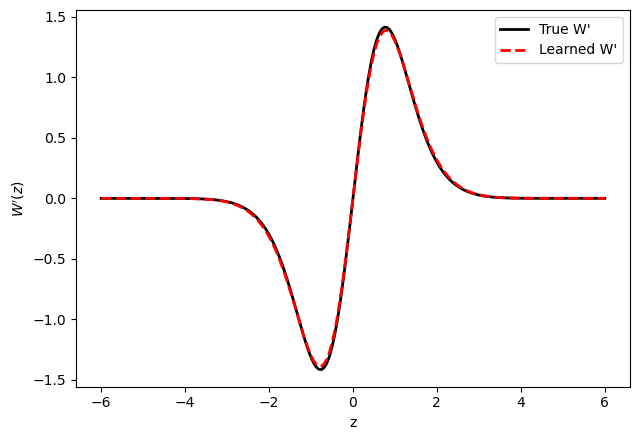


Basis: fourier
A shape: (20, 20)
cond(A): 19522721983.90813
coherence: 0.9722485433583217

PartInv final support: [0 1 2 3 4 6 7 8]
Candidate support: [0, 1, 2, 3, 4, 6, 7, 8]

Best RE support: (0, 1, 2, 3, 4, 6, 7, 8)
Best RE: -0.17982154323952051
Residual: 9.114383514131021e-05

Recovered active terms:
index=0, param=1, coef=+8.757807946099e-01
index=1, param=2, coef=-4.030542025594e-01
index=2, param=3, coef=+1.256899712926e+00
index=3, param=4, coef=-2.095815231150e-01
index=4, param=5, coef=+3.806163541849e-01
index=6, param=7, coef=+2.012490288607e-01
index=7, param=8, coef=-2.194607396142e-01
index=8, param=9, coef=+1.444680089413e-01

Relative L2 errors of W
[-2,2] : 6.667231e-03
[-4,4] : 3.821071e-02
[-6,6] : 1.599413e+00

Relative L2 errors of W'
[-2,2] : 3.236913e-02
[-4,4] : 3.003167e-01
[-6,6] : 1.825847e+00


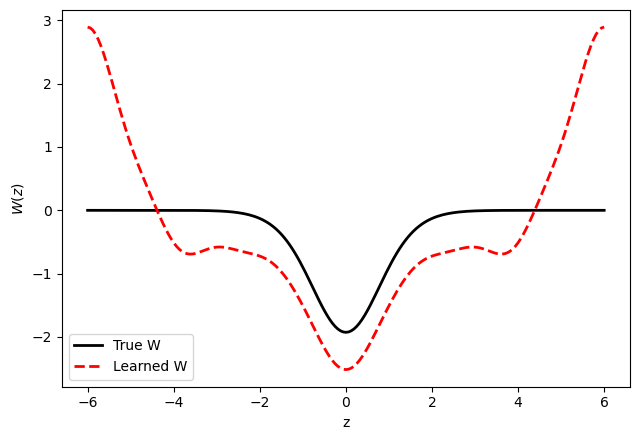

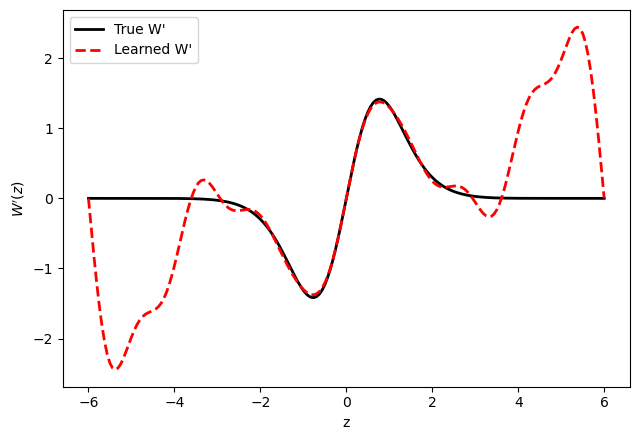


Basis: polynomial
A shape: (6, 6)
cond(A): 20292123065.649597
coherence: 0.9764148859780586

PartInv final support: [0 1 2 3 4 5]
Candidate support: [0, 1, 2, 3, 4, 5]

Best RE support: (0, 1, 2, 3, 4, 5)
Best RE: -0.17922945009823146
Residual: 2.865753675886111e-14

Recovered active terms:
index=0, param=1, coef=+9.553841365406e+01
index=1, param=3, coef=-2.096731259822e+03
index=2, param=5, coef=+1.759957392481e+04
index=3, param=7, coef=-6.742069860590e+04
index=4, param=9, coef=+1.160707755021e+05
index=5, param=11, coef=-7.183299733949e+04

Relative L2 errors of W
[-2,2] : 1.386009e-02
[-4,4] : 1.353109e-01
[-6,6] : 8.338084e+01

Relative L2 errors of W'
[-2,2] : 6.866333e-02
[-4,4] : 4.321000e-01
[-6,6] : 3.920965e+02


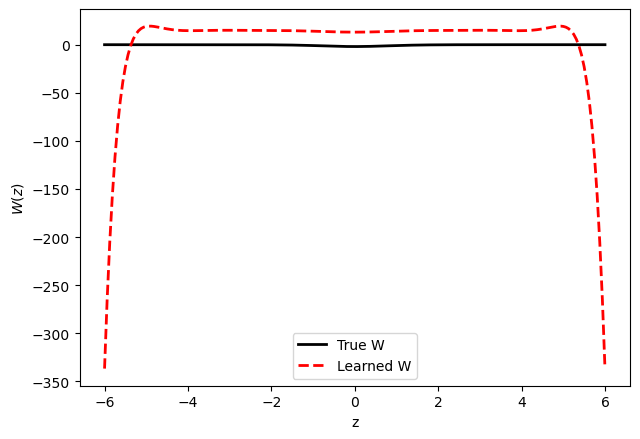

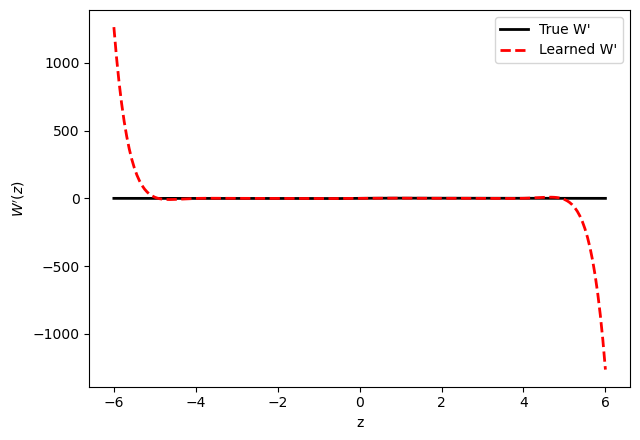



Summary
gaussian           W[-2,2]=7.1001e-03, W[-4,4]=9.8843e-03, W[-6,6]=1.1229e-02, W'[-2,2]=2.1024e-02, W'[-4,4]=2.2163e-02, W'[-6,6]=2.2163e-02, support=(0, 1)
fourier            W[-2,2]=6.6672e-03, W[-4,4]=3.8211e-02, W[-6,6]=1.5994e+00, W'[-2,2]=3.2369e-02, W'[-4,4]=3.0032e-01, W'[-6,6]=1.8258e+00, support=(0, 1, 2, 3, 4, 6, 7, 8)
polynomial         W[-2,2]=1.3860e-02, W[-4,4]=1.3531e-01, W[-6,6]=8.3381e+01, W'[-2,2]=6.8663e-02, W'[-4,4]=4.3210e-01, W'[-6,6]=3.9210e+02, support=(0, 1, 2, 3, 4, 5)


In [11]:
data_file = "example2_sparse_Cx5_Ct250.npz"
tag = os.path.splitext(os.path.basename(data_file))[0]
data = np.load(data_file)
x = data["x_obs"]
t = data["obs_times"]
rho = data["obs_snapshots"]
m = int(data["m"])
kappa = float(data["kappa"])
dx = x[1] - x[0]
Nx = len(x)
offsets = make_offsets(Nx, dx)

print("Loaded:", data_file)
print("rho shape:", rho.shape)
print("x range:", x.min(), x.max())
print("dx:", dx)
print("t range:", t[0], t[-1])
print("dt:", t[1] - t[0])
print("m:", m)
print("kappa:", kappa)
print("offset range:", offsets.min(), offsets.max())


# Build three basis sets
# Build three global basis sets

basis_gaussian = build_gaussian_basis(
    offsets
)

basis_fourier = build_fourier_basis(
    offsets,
    Lbox=6.0,
    num_modes=20,
)

basis_polynomial = build_polynomial_basis(
    offsets,
    powers=np.array([1, 3, 5, 7, 9, 11]),
    Lbox=6.0,
)

os.makedirs("figures_sparse", exist_ok=True)
results = {}

results["gaussian"] = run_one_basis(
    basis_gaussian,
    rho=rho,
    x=x,
    t=t,
    m=m,
    kappa=kappa,
    K_partinv=4,
    sparsity=2,
    output_root="figures_sparse",
    tag=tag,
)

results["fourier"] = run_one_basis(
    basis_fourier,
    rho=rho,
    x=x,
    t=t,
    m=m,
    kappa=kappa,
    K_partinv=8,
    sparsity=8,
    output_root="figures_sparse",
    tag=tag,
)

results["polynomial"] = run_one_basis(
    basis_polynomial,
    rho=rho,
    x=x,
    t=t,
    m=m,
    kappa=kappa,
    K_partinv=6,
    sparsity=6,
    output_root="figures_sparse",
    tag=tag,
)

print("\n\nSummary")
print("=" * 100)

for key, res in results.items():
    print(
        f"{key:18s} "
        f"W[-2,2]={res['W_error_2']:.4e}, "
        f"W[-4,4]={res['W_error_4']:.4e}, "
        f"W[-6,6]={res['W_error_6']:.4e}, "
        f"W'[-2,2]={res['Wp_error_2']:.4e}, " 
        f"W'[-4,4]={res['Wp_error_4']:.4e}, "  
        f"W'[-6,6]={res['Wp_error_6']:.4e}, "
        f"support={res['support']}"
    )

Loaded: example2_sparse_Cx2_Ct50.npz
rho shape: (301, 480)
x range: -5.99375 5.981250000000001
dx: 0.025000000000000355
t range: 0.0 1.5
dt: 0.005
m: 3
kappa: 0.48
offset range: -11.97500000000017 11.97500000000017

Basis: gaussian
A shape: (10, 10)
cond(A): 4.565025448559844e+16
coherence: 0.9996271264456721

PartInv final support: [0 1 2 3]
Candidate support: [0, 1, 2, 3]

Best RE support: (0, 1)
Best RE: -0.18184183516144725
Residual: 1.0399833978664472e-06

Recovered active terms:
index=0, param=0.5, coef=+4.889523559740e+00
index=1, param=1.0, coef=+1.332058815986e+01

Relative L2 errors of W
[-2,2] : 1.500673e-03
[-4,4] : 1.868133e-03
[-6,6] : 2.075647e-03

Relative L2 errors of W'
[-2,2] : 4.188478e-03
[-4,4] : 4.408732e-03
[-6,6] : 4.408737e-03


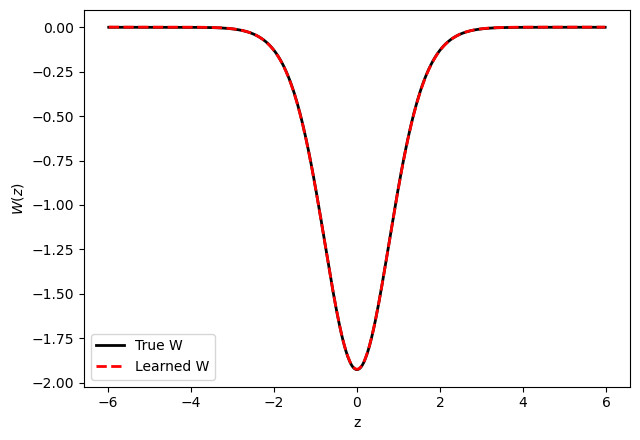

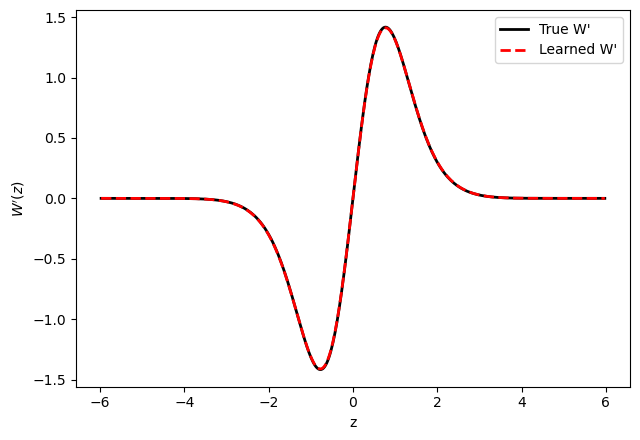


Basis: fourier
A shape: (20, 20)
cond(A): 20261272252.49319
coherence: 0.9724013590380468

PartInv final support: [0 1 2 4 6 7]
Candidate support: [0, 1, 2, 4, 6, 7]

Best RE support: (0, 1, 2, 4, 6, 7)
Best RE: -0.18184213359227158
Residual: 1.7869223067203575e-05

Recovered active terms:
index=0, param=1, coef=+4.797373883774e-01
index=1, param=2, coef=+1.766278718983e-01
index=2, param=3, coef=+7.788017414181e-01
index=4, param=5, coef=+3.944930962892e-01
index=6, param=7, coef=+5.758068321941e-02
index=7, param=8, coef=+2.748557213915e-02

Relative L2 errors of W
[-2,2] : 1.026887e-03
[-4,4] : 8.604094e-03
[-6,6] : 5.286351e-01

Relative L2 errors of W'
[-2,2] : 4.088525e-03
[-4,4] : 3.671687e-02
[-6,6] : 7.644916e-01


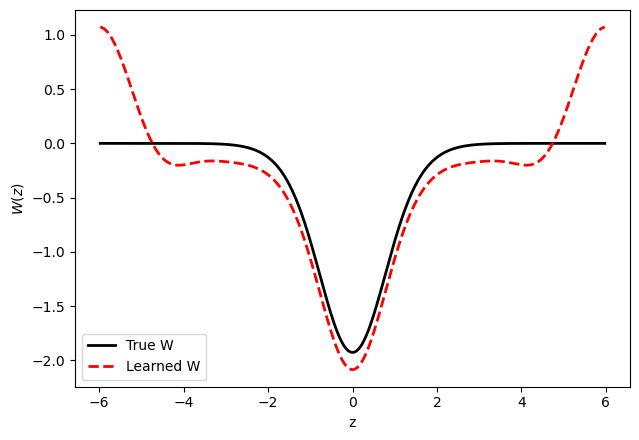

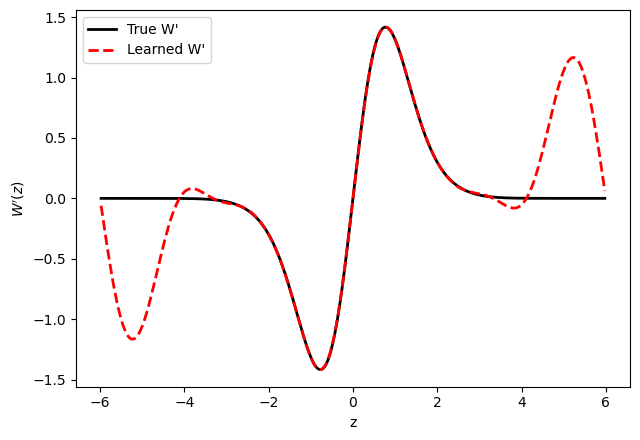


Basis: polynomial
A shape: (6, 6)
cond(A): 20652548990.554527
coherence: 0.9762423117311368

PartInv final support: [0 1 2 3]
Candidate support: [0, 1, 2, 3]

Best RE support: (0, 1, 2, 3)
Best RE: -0.17887173452524385
Residual: 9.578952886886945e-08

Recovered active terms:
index=0, param=1, coef=+7.067874665055e+01
index=1, param=3, coef=-1.010001444743e+03
index=2, param=5, coef=+4.417442387848e+03
index=3, param=7, coef=-5.700476296793e+03

Relative L2 errors of W
[-2,2] : 6.050954e-02
[-4,4] : 3.138987e-01
[-6,6] : 5.331425e+01

Relative L2 errors of W'
[-2,2] : 2.111893e-01
[-4,4] : 7.511271e-01
[-6,6] : 1.402432e+02


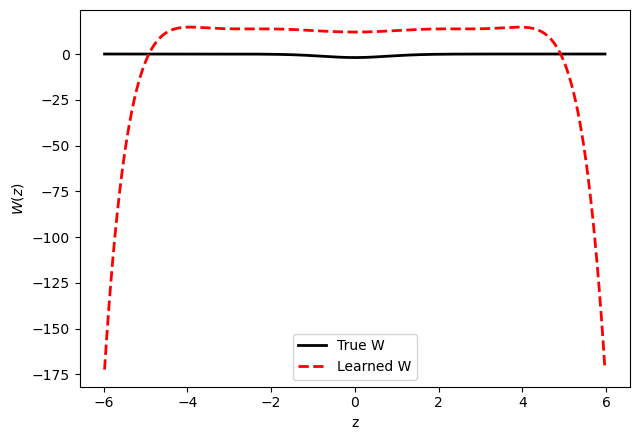

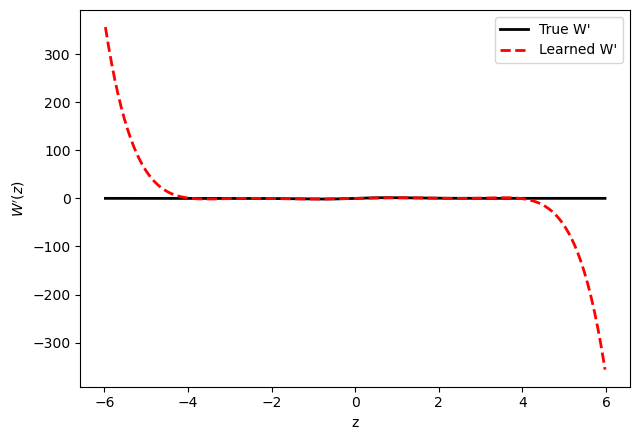



Summary
gaussian           W[-2,2]=1.5007e-03, W[-4,4]=1.8681e-03, W[-6,6]=2.0756e-03, W'[-2,2]=4.1885e-03, W'[-4,4]=4.4087e-03, W'[-6,6]=4.4087e-03, support=(0, 1)
fourier            W[-2,2]=1.0269e-03, W[-4,4]=8.6041e-03, W[-6,6]=5.2864e-01, W'[-2,2]=4.0885e-03, W'[-4,4]=3.6717e-02, W'[-6,6]=7.6449e-01, support=(0, 1, 2, 4, 6, 7)
polynomial         W[-2,2]=6.0510e-02, W[-4,4]=3.1390e-01, W[-6,6]=5.3314e+01, W'[-2,2]=2.1119e-01, W'[-4,4]=7.5113e-01, W'[-6,6]=1.4024e+02, support=(0, 1, 2, 3)


In [12]:
data_file = "example2_sparse_Cx2_Ct50.npz"
tag = os.path.splitext(os.path.basename(data_file))[0]
data = np.load(data_file)
x = data["x_obs"]
t = data["obs_times"]
rho = data["obs_snapshots"]
m = int(data["m"])
kappa = float(data["kappa"])
dx = x[1] - x[0]
Nx = len(x)
offsets = make_offsets(Nx, dx)

print("Loaded:", data_file)
print("rho shape:", rho.shape)
print("x range:", x.min(), x.max())
print("dx:", dx)
print("t range:", t[0], t[-1])
print("dt:", t[1] - t[0])
print("m:", m)
print("kappa:", kappa)
print("offset range:", offsets.min(), offsets.max())


# Build three basis sets
basis_gaussian = build_gaussian_basis(offsets)
basis_fourier = build_fourier_basis(
    offsets,
    Lbox=6.0,
    num_modes=20,
)
basis_polynomial = build_polynomial_basis(
    offsets,
    powers=np.array([1, 3, 5, 7, 9, 11]),
)

os.makedirs("figures_sparse", exist_ok=True)
results = {}
results["gaussian"] = run_one_basis(
    basis_gaussian,
    rho=rho,
    x=x,
    t=t,
    m=m,
    kappa=kappa,
    K_partinv=4,
    sparsity=2,
    output_root="figures_sparse",
    tag=tag,
)

results["fourier"] = run_one_basis(
    basis_fourier,
    rho=rho,
    x=x,
    t=t,
    m=m,
    kappa=kappa,
    K_partinv=6,
    sparsity=6,
    output_root="figures_sparse",
    tag=tag,
)

results["polynomial"] = run_one_basis(
    basis_polynomial,
    rho=rho,
    x=x,
    t=t,
    m=m,
    kappa=kappa,
    K_partinv=4,
    sparsity=4,
    output_root="figures_sparse",
    tag=tag,   
)

print("\n\nSummary")
print("=" * 100)

for key, res in results.items():
    print(
        f"{key:18s} "
        f"W[-2,2]={res['W_error_2']:.4e}, "
        f"W[-4,4]={res['W_error_4']:.4e}, "
        f"W[-6,6]={res['W_error_6']:.4e}, "
        f"W'[-2,2]={res['Wp_error_2']:.4e}, " 
        f"W'[-4,4]={res['Wp_error_4']:.4e}, "  
        f"W'[-6,6]={res['Wp_error_6']:.4e}, "
        f"support={res['support']}"
    )
